In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler,OrdinalEncoder
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score,f1_score

In [4]:
df=pd.read_csv("/content/student_performance.csv")

In [5]:
df.head(5)

,Age,Gender,Family_Income,Parents_Education,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,School_Type,Class_Size,Performance_Level
0,19,Male,63900.28,High School,16.90,81.47,80.74,84.96,69.20,2.63,8.96,4.67,2.89,17.91,Public,37.0,Average
1,17,Female,73037.15,Bachelor,13.15,100.00,99.35,93.13,84.13,3.63,6.24,1.03,1.24,0.00,Public,18.0,Good
2,19,Female,200000.00,Master,20.38,89.40,100.00,83.40,91.43,3.89,7.49,1.55,6.86,0.00,Public,29.0,Good
3,22,Male,139052.26,Bachelor,24.60,65.24,94.36,79.22,82.67,3.29,7.78,6.36,2.43,0.00,Public,19.0,Good
4,17,Female,15093.05,Master,13.67,99.49,100.00,89.16,92.38,3.19,10.00,7.60,5.30,30.00,Public,50.0,Poor


In [6]:
df.shape

(138521, 17)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138521 entries, 0 to 138520
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Age                  138521 non-null  int64  
 1   Gender               138521 non-null  object 
 2   Family_Income        138521 non-null  float64
 3   Parents_Education    138521 non-null  object 
 4   Study_Hours_Week     138521 non-null  float64
 5   Attendance_Percent   138521 non-null  float64
 6   Assignment_Score     138521 non-null  float64
 7   Midterm_Score        138521 non-null  float64
 8   Final_Score          138521 non-null  float64
 9   Previous_GPA         138521 non-null  float64
 10  Sleep_Hours          138521 non-null  float64
 11  Exercise_Hours_Week  138520 non-null  float64
 12  Social_Media_Hours   138520 non-null  float64
 13  Part_Time_Job_Hours  138520 non-null  float64
 14  School_Type          138520 non-null  object 
 15  Class_Size       

In [8]:
df.isnull().sum()

,0
Age,0
Gender,0
Family_Income,0
Parents_Education,0
Study_Hours_Week,0
Attendance_Percent,0
Assignment_Score,0
Midterm_Score,0
Final_Score,0
Previous_GPA,0


In [9]:
df.dropna(axis=0,inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,Age,Family_Income,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,Class_Size
count,138520.000000,138520.000000,138520.000000,138520.000000,138520.000000,138520.000000,138520.00000,138520.000000,138520.000000,138520.000000,138520.000000,138520.000000,138520.000000
mean,17.836616,58251.845056,15.929878,84.408330,87.064924,79.329266,75.33390,3.110703,6.988403,3.996951,4.430863,4.501822,27.719023
std,2.494282,36057.370626,7.797548,10.915372,11.061062,12.801204,13.28298,0.443406,1.463915,2.787157,2.381762,8.368836,7.596188
min,15.000000,10000.000000,0.590000,30.840000,39.670000,19.140000,13.11000,1.080000,3.000000,0.000000,0.030000,0.000000,15.000000
25%,15.000000,32750.255000,10.120000,76.920000,79.030000,70.640000,66.36000,2.810000,5.990000,1.920000,2.590000,0.000000,22.000000
50%,18.000000,49108.985000,14.650000,85.020000,88.100000,80.010000,75.91000,3.130000,7.000000,3.370000,4.020000,0.000000,28.000000
75%,20.000000,73595.762500,20.450000,93.120000,98.250000,88.990000,85.01000,3.430000,8.010000,5.390000,5.900000,5.980000,33.000000
max,25.000000,200000.000000,40.000000,100.000000,100.000000,100.000000,100.00000,4.000000,10.000000,15.000000,10.000000,30.000000,50.000000


In [12]:
num=df.select_dtypes(include="number")
corr=num.corr()
corr

,Age,Family_Income,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,Class_Size
Age,1.000000,0.000379,0.001160,0.001068,0.000956,-0.000859,-0.003326,0.001538,-0.004004,0.004219,0.003653,0.004815,0.001549
Family_Income,0.000379,1.000000,-0.001020,0.001021,-0.000481,0.000286,-0.001653,-0.000931,-0.001642,-0.004996,-0.003790,0.000019,-0.003635
Study_Hours_Week,0.001160,-0.001020,1.000000,-0.000590,0.711487,0.471382,0.382659,0.526126,0.001479,-0.000998,-0.000232,0.000690,-0.002761
Attendance_Percent,0.001068,0.001021,-0.000590,1.000000,0.235474,0.157701,0.129171,0.175271,-0.002068,0.000884,-0.000120,0.004355,-0.001628
Assignment_Score,0.000956,-0.000481,0.711487,0.235474,1.000000,0.669441,0.545233,0.744357,0.001598,-0.000550,-0.002180,0.000495,-0.002193
Midterm_Score,-0.000859,0.000286,0.471382,0.157701,0.669441,1.000000,0.807557,0.496583,0.001777,0.000903,-0.002263,0.000463,-0.001475
Final_Score,-0.003326,-0.001653,0.382659,0.129171,0.545233,0.807557,1.000000,0.404762,0.000478,0.003000,-0.003281,0.000150,0.001374
Previous_GPA,0.001538,-0.000931,0.526126,0.175271,0.744357,0.496583,0.404762,1.000000,0.003012,-0.000327,-0.000494,0.000903,-0.003297
Sleep_Hours,-0.004004,-0.001642,0.001479,-0.002068,0.001598,0.001777,0.000478,0.003012,1.000000,-0.000420,0.000217,-0.000358,-0.001281
Exercise_Hours_Week,0.004219,-0.004996,-0.000998,0.000884,-0.000550,0.000903,0.003000,-0.000327,-0.000420,1.000000,-0.001414,-0.000553,-0.000734


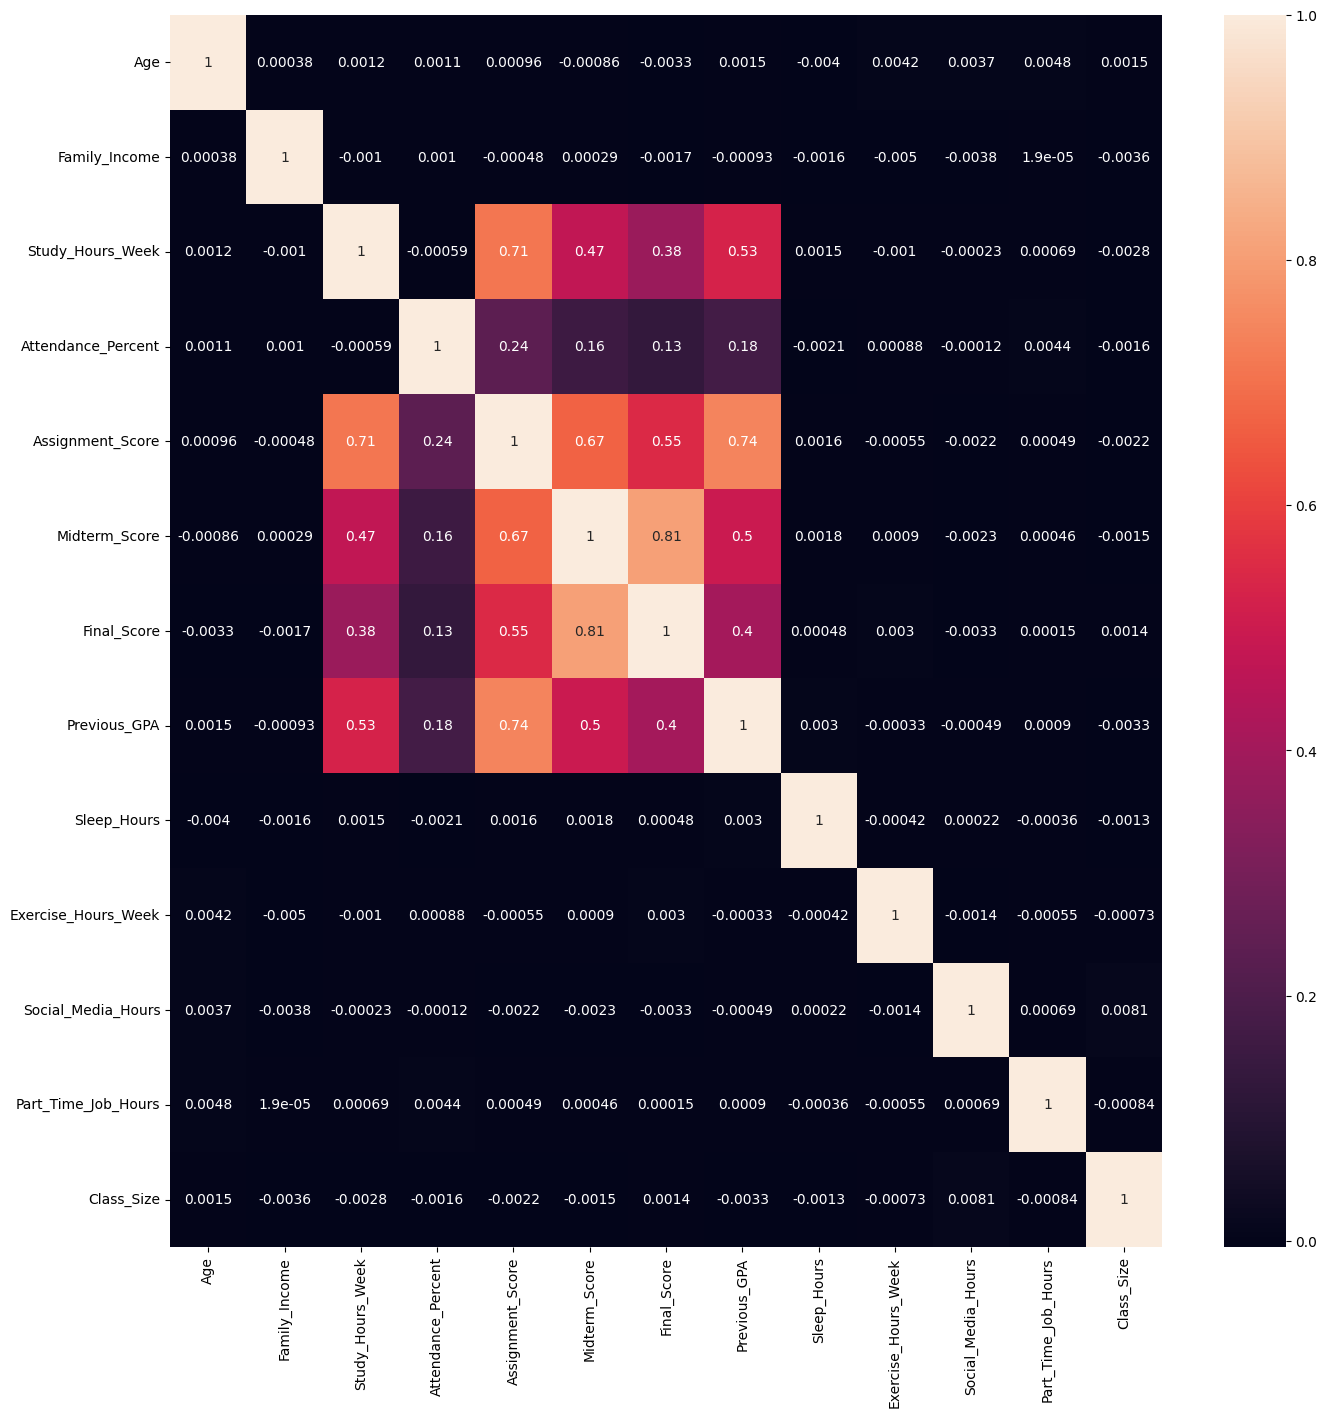

In [13]:
plt.figure(figsize=(16,16))
sns.heatmap(corr,annot=True)
plt.show()

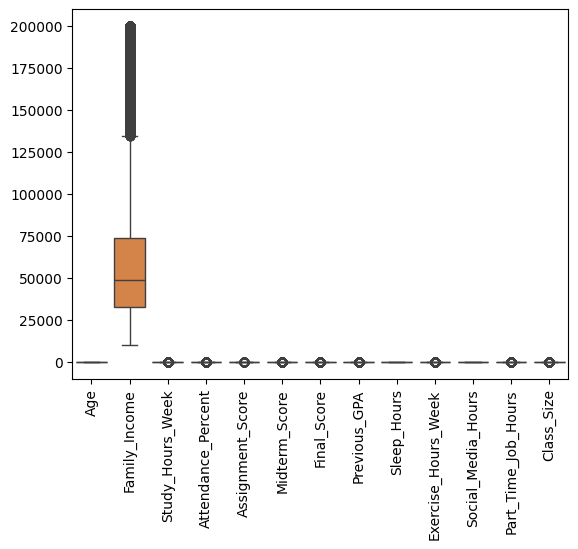

In [14]:
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.show()

In [15]:
df.head(2)

,Age,Gender,Family_Income,Parents_Education,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,School_Type,Class_Size,Performance_Level
0,19,Male,63900.28,High School,16.90,81.47,80.74,84.96,69.20,2.63,8.96,4.67,2.89,17.91,Public,37.0,Average
1,17,Female,73037.15,Bachelor,13.15,100.00,99.35,93.13,84.13,3.63,6.24,1.03,1.24,0.00,Public,18.0,Good


In [16]:
df["Age"].mean()

np.float64(17.836615651169506)

In [17]:
df["Gender"].value_counts()

,count
Gender,
Female,69350
Male,69170


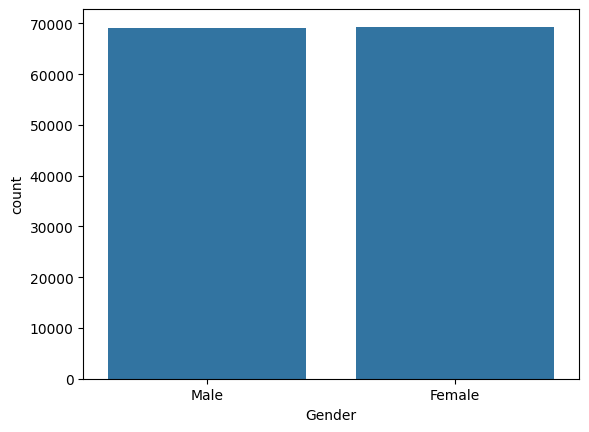

In [18]:
sns.countplot(data=df,x="Gender")
plt.show()

In [19]:
df["Parents_Education"].value_counts()

,count
Parents_Education,
Bachelor,62515
High School,41456
Master,27685
PhD,6864


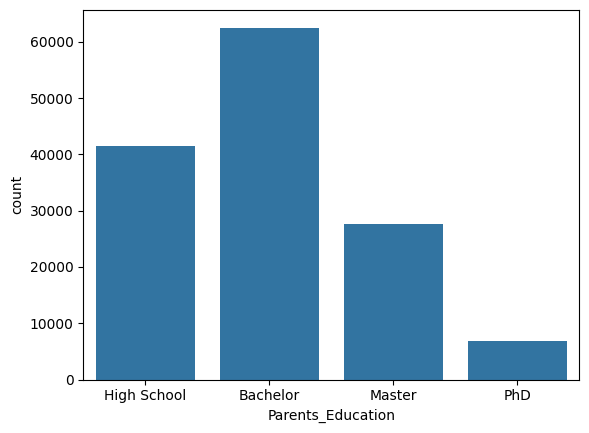

In [20]:
sns.countplot(data=df,x="Parents_Education")
plt.show()

In [21]:
inc_edu=df.groupby("Parents_Education")["Family_Income"].mean().sort_values(ascending=False).reset_index()
inc_edu

,Parents_Education,Family_Income
0,PhD,59580.956161
1,Master,58223.122660
2,High School,58222.012722
3,Bachelor,58138.414523


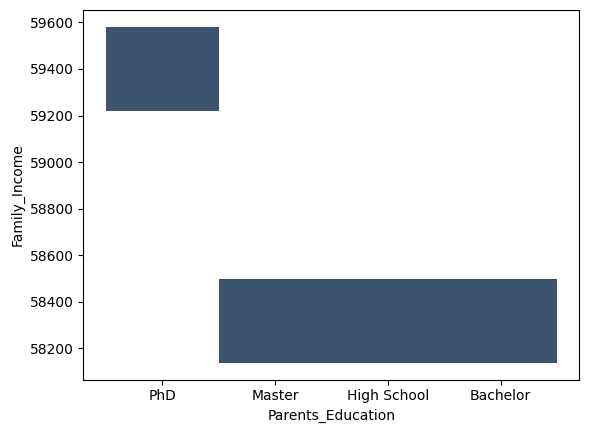

In [22]:
sns.histplot(x="Parents_Education",y="Family_Income",data=inc_edu)
plt.show()

In [23]:
df.head(2)

,Age,Gender,Family_Income,Parents_Education,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,School_Type,Class_Size,Performance_Level
0,19,Male,63900.28,High School,16.90,81.47,80.74,84.96,69.20,2.63,8.96,4.67,2.89,17.91,Public,37.0,Average
1,17,Female,73037.15,Bachelor,13.15,100.00,99.35,93.13,84.13,3.63,6.24,1.03,1.24,0.00,Public,18.0,Good


In [24]:
tye_final=df.groupby("School_Type")["Final_Score"].mean().sort_values(ascending=False).reset_index()
tye_final

,School_Type,Final_Score
0,Charter,75.502051
1,Private,75.401167
2,Public,75.273075


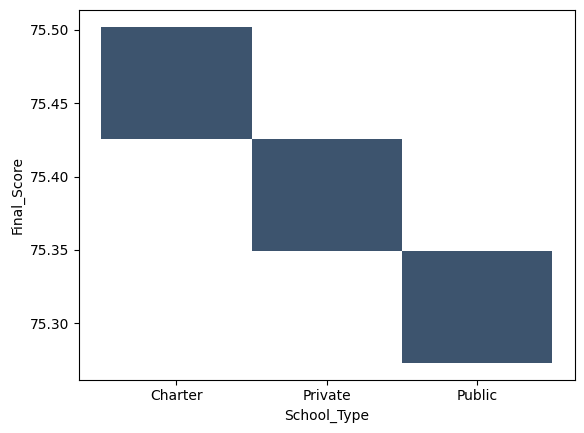

In [25]:
sns.histplot(x="School_Type",y="Final_Score",data=tye_final,kde=True)
plt.show()

In [26]:
fin_pre=df.groupby("Performance_Level")["Final_Score"].mean().sort_values().reset_index()

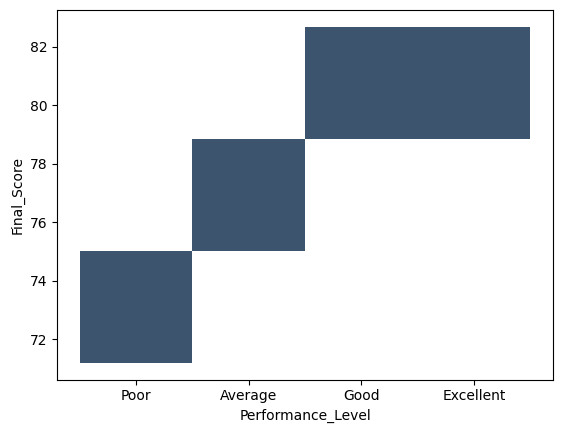

In [27]:
sns.histplot(x="Performance_Level",y="Final_Score",data=fin_pre,kde=True)
plt.show()

In [28]:
sleep_pre=df.groupby("Performance_Level")["Sleep_Hours"].mean().sort_values().reset_index()
sleep_pre

,Performance_Level,Sleep_Hours
0,Poor,6.896294
1,Average,7.022455
2,Good,7.052639
3,Excellent,7.128672


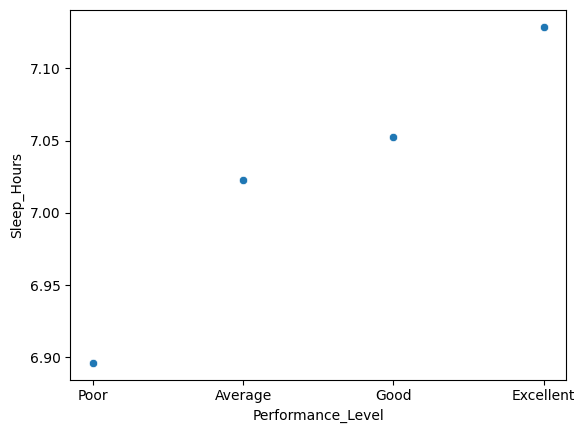

In [29]:
sns.scatterplot(x="Performance_Level",y="Sleep_Hours",data=sleep_pre)
plt.show()

In [30]:
mean_pre = df.groupby("Performance_Level")[
    ["Final_Score", "Sleep_Hours", "Social_Media_Hours", "Part_Time_Job_Hours"]
].agg(["mean", "sum"]).sort_values(by=("Final_Score", "mean"), ascending=False).reset_index()

mean_pre

Performance_Level Final_Score             Sleep_Hours             \
                           mean         sum        mean        sum   
0         Excellent   82.683067  1149542.68    7.128672   99109.92   
1              Good   79.786423  2192610.69    7.052639  193813.57   
2           Average   75.471571  3129655.09    7.022455  291207.17   
3              Poor   71.197877  3963443.39    6.896294  383902.89   

  Social_Media_Hours            Part_Time_Job_Hours             
                mean        sum                mean        sum  
0           3.222423   44801.35            2.450708   34072.20  
1           3.676778  101041.54            3.307966   90906.20  
2           4.117552  170746.65            4.265848  176896.20  
3           5.338319  297173.55            5.779223  321717.79

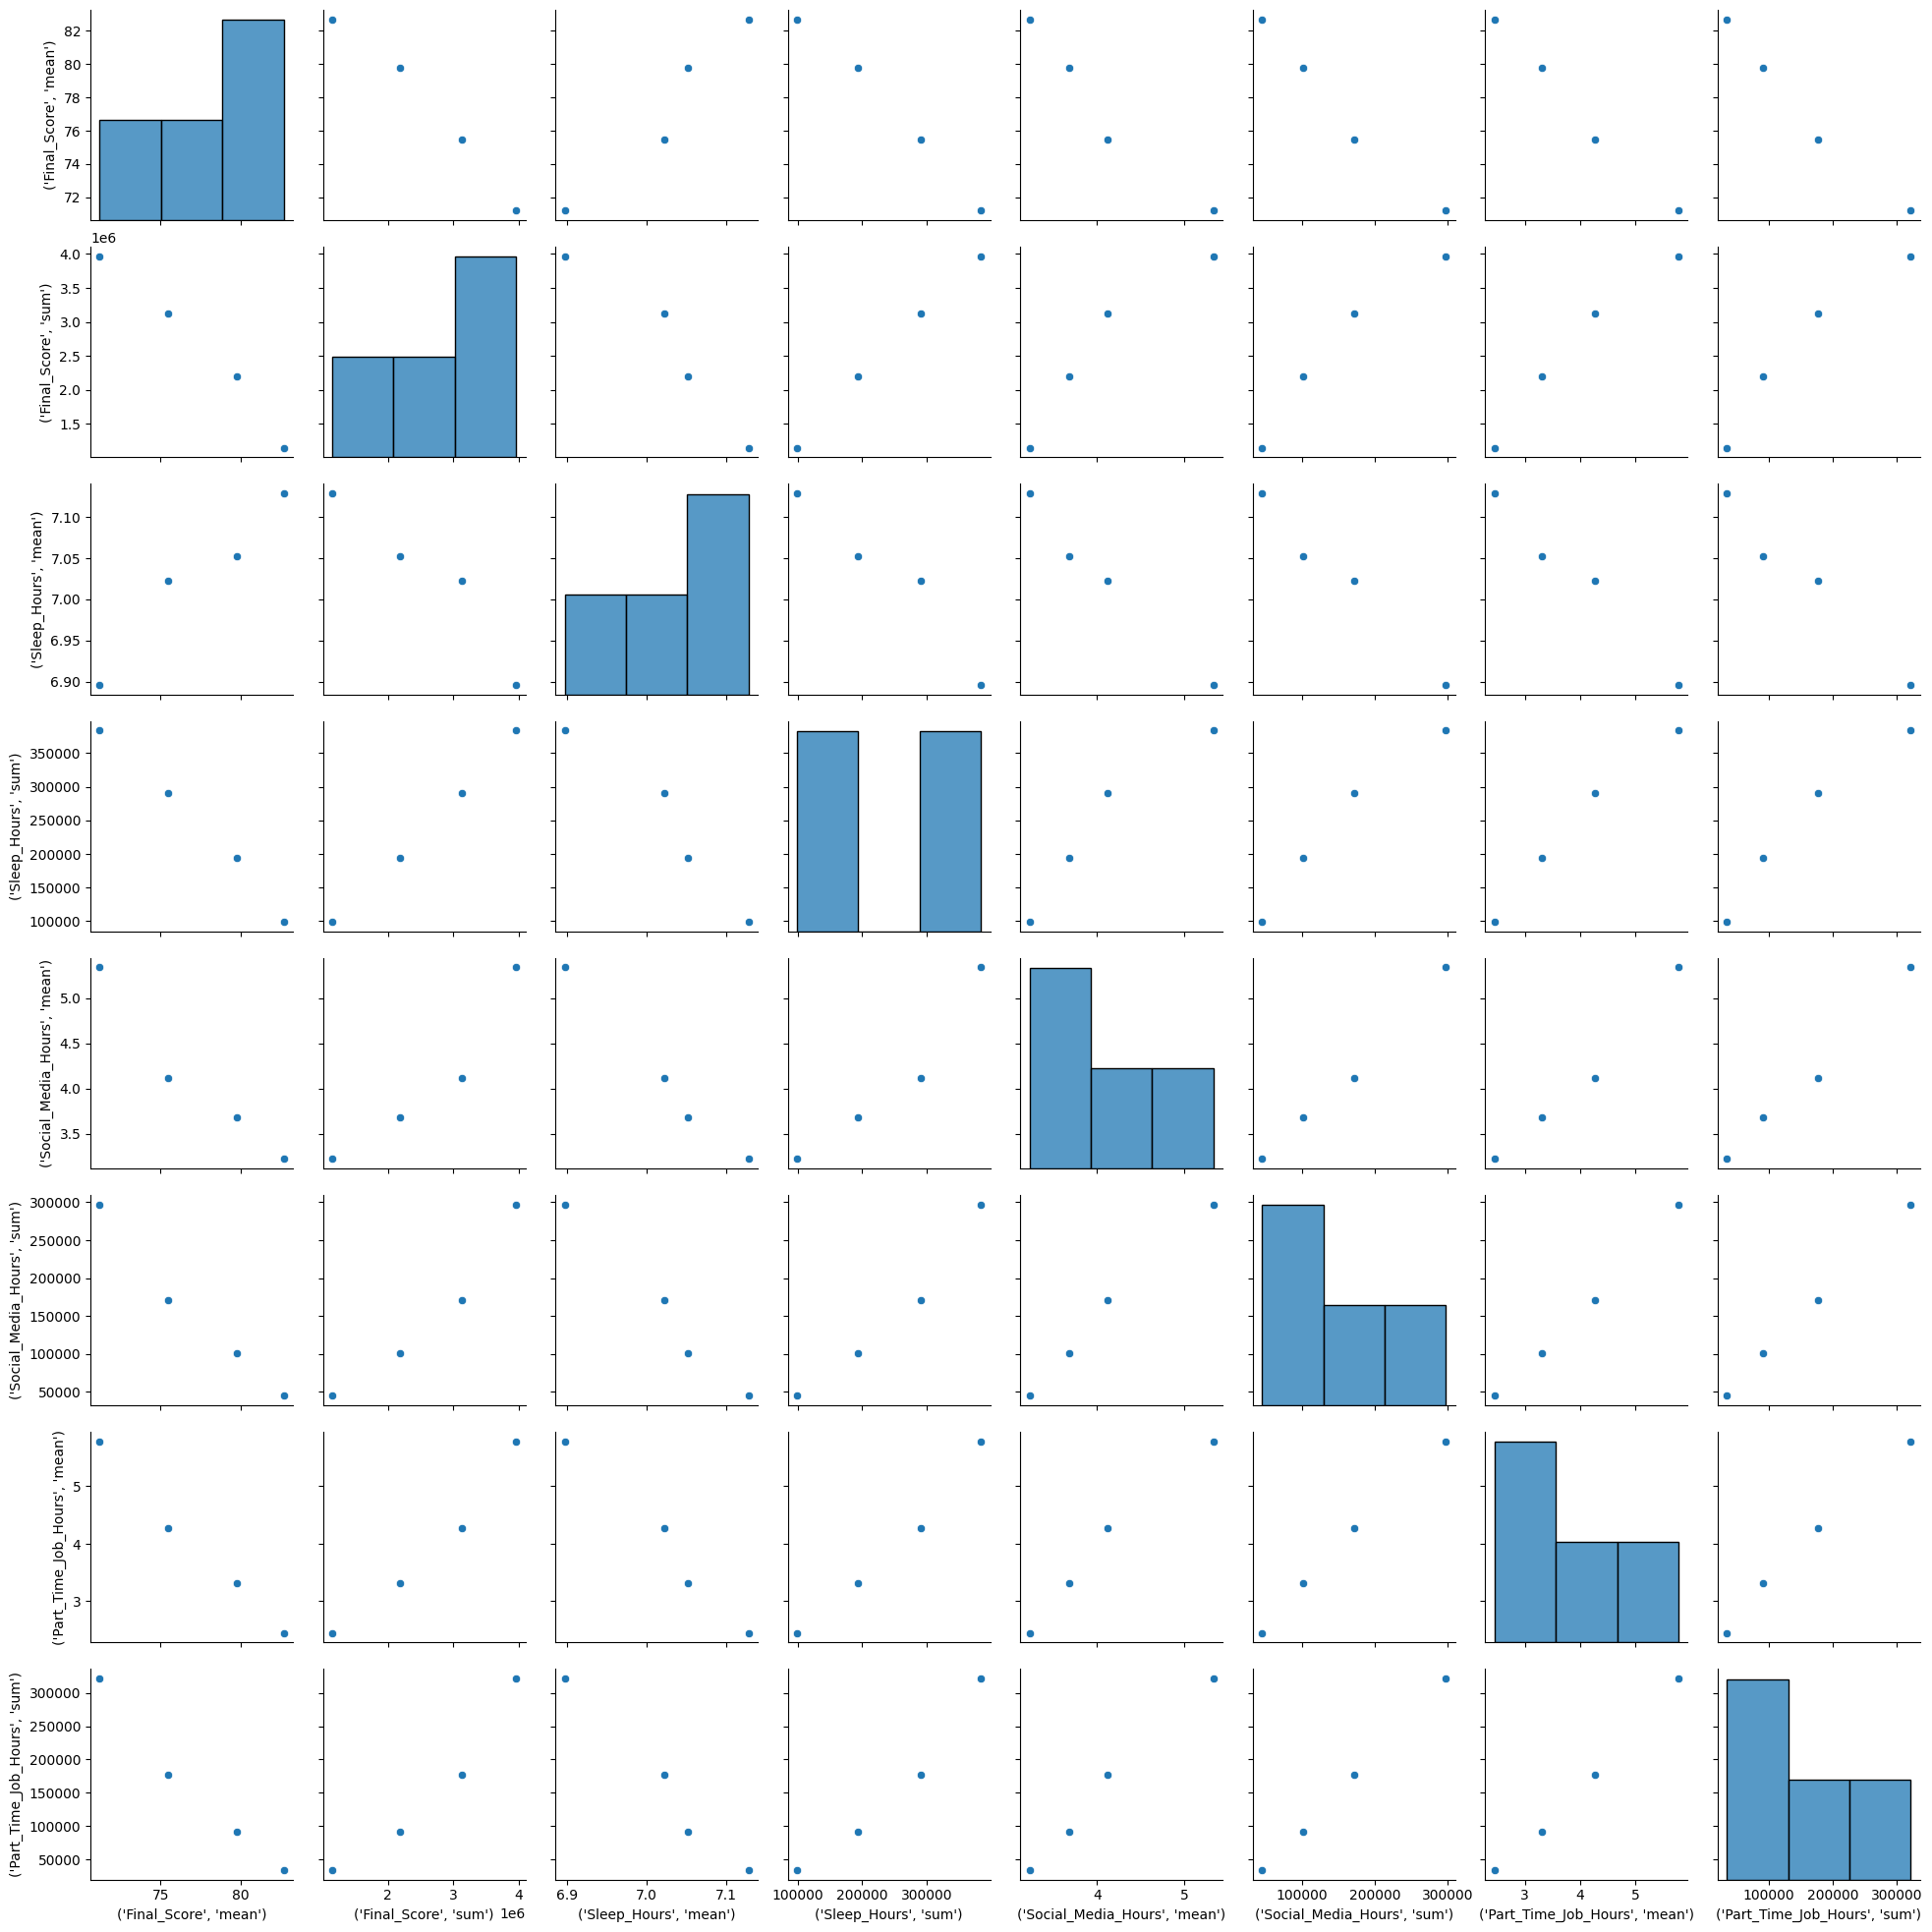

In [31]:
sns.pairplot(data=mean_pre)
plt.show()

In [32]:
encoder=OrdinalEncoder()
df["Performance_Level"]=encoder.fit_transform(df[["Performance_Level"]])
df.head()

,Age,Gender,Family_Income,Parents_Education,Study_Hours_Week,Attendance_Percent,Assignment_Score,Midterm_Score,Final_Score,Previous_GPA,Sleep_Hours,Exercise_Hours_Week,Social_Media_Hours,Part_Time_Job_Hours,School_Type,Class_Size,Performance_Level
0,19,Male,63900.28,High School,16.90,81.47,80.74,84.96,69.20,2.63,8.96,4.67,2.89,17.91,Public,37.0,0.0
1,17,Female,73037.15,Bachelor,13.15,100.00,99.35,93.13,84.13,3.63,6.24,1.03,1.24,0.00,Public,18.0,2.0
2,19,Female,200000.00,Master,20.38,89.40,100.00,83.40,91.43,3.89,7.49,1.55,6.86,0.00,Public,29.0,2.0
3,22,Male,139052.26,Bachelor,24.60,65.24,94.36,79.22,82.67,3.29,7.78,6.36,2.43,0.00,Public,19.0,2.0
4,17,Female,15093.05,Master,13.67,99.49,100.00,89.16,92.38,3.19,10.00,7.60,5.30,30.00,Public,50.0,3.0


In [33]:
x=df.drop(columns=["Performance_Level"])
y=df["Performance_Level"]

In [34]:
y.value_counts()

,count
Performance_Level,
3.0,55668
0.0,41468
2.0,27481
1.0,13903


In [35]:
rm=RandomOverSampler()
x,y=rm.fit_resample(x,y)

In [36]:
y.value_counts()

,count
Performance_Level,
0.0,55668
2.0,55668
3.0,55668
1.0,55668


In [37]:
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.30,random_state=42,stratify=y)
x_val,x_test,y_val,y_test=train_test_split(x_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)

In [38]:
encoder=OrdinalEncoder()
obj=x_train.select_dtypes(include="object").columns
x_train[obj]=encoder.fit_transform(x_train[obj])
x_val[obj]=encoder.transform(x_val[obj])
x_test[obj]=encoder.transform(x_test[obj])

In [39]:
scaler=MinMaxScaler()
num=x_train.select_dtypes(include="number").columns
x_train[num]=scaler.fit_transform(x_train[num])
x_val[num]=scaler.transform(x_val[num])
x_test[num]=scaler.transform(x_test[num])

In [40]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,DataLoader
torch.manual_seed(42)

In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [42]:
x_train=torch.tensor(x_train.values,dtype=torch.float32).to(device)
y_train=torch.tensor(y_train.values,dtype=torch.long).to(device)
x_val=torch.tensor(x_val.values,dtype=torch.float32).to(device)
y_val=torch.tensor(y_val.values,dtype=torch.long).to(device)
x_test=torch.tensor(x_test.values,dtype=torch.float32).to(device)
y_test=torch.tensor(y_test.values,dtype=torch.long).to(device)

In [43]:
BATCH_SIZE=512
train=TensorDataset(x_train,y_train)
val=TensorDataset(x_val,y_val)
test=TensorDataset(x_test,y_test)

In [44]:
train_loader=DataLoader(train,batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(val,batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(test,batch_size=BATCH_SIZE,shuffle=False)

In [45]:
class multi_class(nn.Module):
  def __init__(self,input_size):
    super().__init__()
    self.network=nn.Sequential(
        nn.Linear(input_size,564),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(564,256),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(256,128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64,4)
    )
  def forward(self,x):
    return self.network(x)

In [46]:
model=multi_class(x_train.shape[1]).to(device)

In [47]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.01,weight_decay=1e-5)
scadular=optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min",factor=0.5,patience=4)

In [48]:
def train_one_epoch(model,loader,criterion,optimizer,device):
  model.train()
  total_loss=0
  all_preds=[]
  all_targets=[]
  for x_batch,y_batch in loader:
    x_batch,y_batch=x_batch.to(device),y_batch.to(device)
    logits=model(x_batch)
    loss=criterion(logits,y_batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_loss+=loss.item()*x_batch.size(0)
    preds=torch.argmax(logits,dim=1)
    all_preds.append(preds.detach().cpu())
    all_targets.append(y_batch.cpu())
  avg_loss=total_loss/len(loader.dataset)
  all_preds=torch.cat(all_preds).numpy().flatten()
  all_targets=torch.cat(all_targets).numpy().flatten()
  accuracy=accuracy_score(all_targets,all_preds)
  return avg_loss,accuracy


In [51]:
def validation(model,loader,criterion,device):
  model.eval()
  total_loss=0
  all_preds=[]
  all_targets=[]
  with torch.no_grad():
    for x_batch,y_batch in loader:
      x_batch,y_batch=x_batch.to(device),y_batch.to(device)
      logits=model(x_batch)
      loss=criterion(logits,y_batch)

      total_loss+=loss.item()*x_batch.size(0)
      preds=torch.argmax(logits,dim=1)
      all_preds.append(preds.cpu())
      all_targets.append(y_batch.cpu())

  avg_loss=total_loss/len(loader.dataset)
  all_preds=torch.cat(all_preds).numpy().flatten()
  all_targets=torch.cat(all_targets).numpy().flatten()
  accuracy=accuracy_score(all_targets,all_preds)
  return avg_loss,accuracy,all_preds,all_targets

In [53]:
num_epoch=80
PATIANCE=7
train_losses=[]
train_accs=[]
val_losses=[]
val_accs=[]
best_model_state=None
best_val_loss=float("inf")
patiant_counter=0

for epoch in range(num_epoch):
  train_loss,train_acc=train_one_epoch(model,train_loader,criterion,optimizer,device)
  val_loss,val_acc,_,_=validation(model,val_loader,criterion,device)
  train_losses.append(train_loss)
  train_accs.append(train_acc)
  val_losses.append(val_loss)
  val_accs.append(val_acc)
  current_lr=optimizer.param_groups[0]["lr"]
  scadular.step(val_loss)
  if val_loss<best_val_loss:
    best_val_loss=val_loss
    best_model_state=model.state_dict()
    patiant_counter=0
  else:
    patiant_counter+=1
  if patiant_counter>=PATIANCE:
    f"the epoch is stop on {epoch+1}"
    break
model.load_state_dict(best_model_state)

<All keys matched successfully>

In [54]:
_,_,y_pred_dl,_=validation(model,test_loader,criterion,device)
accuray=accuracy_score(y_test,y_pred_dl)
f1=f1_score(y_test,y_pred_dl,average="macro")
print(f"Accuracy: {accuray}")
print(f"F1 Score: {f1}")

Accuracy: 0.9623963354390587
F1 Score: 0.9624360258317712
